# Phase 1: Market Rent Prediction - Model Development

## Objective

The objective of this notebook is to develop and evaluate machine learning models for predicting residential asking rents using market listing data.

We will begin by examining the available features, reviewing the team's previous feature selection work, and identifying suitable predictors while avoiding data leakage.

We will then train and compare baseline regression models and more flexible machine learning approaches.

**Target variable:** `market_price_observation__first_asking_rent`

**Dataset:** Accolade synthetic master listing dataset.

**Note:** Synthetic data will be used to develop and test the modeling pipeline. Predictive performance on synthetic data should not be interpreted as evidence of real-world accuracy.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Project directory
project_dir = Path.cwd().resolve().parents[1]

# Load master dataset
data_path = project_dir / "data" / "master_listing.parquet"
df = pd.read_parquet(data_path)

print("Dataset shape:", df.shape)
print("Target available:",
      "market_price_observation__first_asking_rent" in df.columns)

Dataset shape: (967661, 378)
Target available: True


## 1. Target Variable Analysis

We first examine the target variable, `market_price_observation__first_asking_rent`, which represents the initial advertised rent for a rental listing.

We assess the number of available observations, missing values, and summary statistics to identify potential data quality issues before model training.

In [2]:
# Define target variable
target = "market_price_observation__first_asking_rent"

# Check target availability and distribution
print("Total observations:", len(df))
print("Non-missing target values:", df[target].notna().sum())
print("Missing target values:", df[target].isna().sum())

print("\nTarget summary:")
print(df[target].describe())

print("\nNon-positive rents:")
print((df[target] <= 0).sum())

Total observations: 967661
Non-missing target values: 967277
Missing target values: 384

Target summary:
count    967277.000000
mean       1857.103647
std         657.902013
min         410.000000
25%        1365.000000
50%        1760.000000
75%        2243.000000
max        6500.000000
Name: market_price_observation__first_asking_rent, dtype: float64

Non-positive rents:
0


### Initial Findings

The dataset contains 967,661 observations, of which 967,277 (99.96%) have a non-missing target value.

The mean asking rent is approximately $1,857, while the median is $1,760. Observed rents range from $410 to $6,500, with no zero or negative values.

Observations with missing target values will be excluded from supervised model training. Potential outliers will be examined before determining whether any additional filtering is necessary.

## 2. Feature Inventory and Data Quality

Before selecting predictors, we examine all available variables in the master dataset.

For each column, we identify its data type and percentage of missing values. This inventory will help us understand the dataset structure and assess feature availability.

Feature selection will also consider the team's previous exploratory analysis, the data dictionary, and whether each variable would be available at the time of prediction.

Particular attention will be paid to preventing data leakage from future pricing information, synthetic ground-truth variables, and property management system (PMS) data.

In [3]:
# Complete inventory of dataset columns
column_inventory = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).values,
    "Missing (%)": df.isna().mean().values * 100
})

pd.set_option("display.max_rows", None)

display(column_inventory.round(2))

,Column,Data type,Missing (%)
0,unit_id,str,0.00
1,property_id,str,0.00
2,floor_plan_id,str,0.00
3,market,str,0.00
4,market_unit__unit_name,str,10.78
5,market_unit__floorplan_name,str,0.00
6,market_unit__bed,int64,0.00
7,market_unit__bath,int64,0.00
8,market_unit__partial_bath,int64,0.00
9,market_unit__floor,float64,49.30


## 3. Feature Selection and Leakage Prevention

We review the available predictors using the data dictionary and the team's previous numerical feature selection results.

Our goal is to identify variables that are relevant for predicting initial asking rents and would be available at the time a listing enters the market.

We exclude variables that are clearly future-dependent or derived from synthetic ground truth. However, the availability of all selected predictors at listing entry still requires verification.

The initial feature set will be evaluated and refined during model development.

In [4]:

# Initial numerical features for market rent prediction
numerical_features = [
    # Unit characteristics
    "market_unit__sqft",
    "market_unit__bed",
    "market_unit__bath",
    "market_unit__floor",

    # Building characteristics
    "market_building__year_built",
    "market_building__number_units",
    "market_building__n_building_amenities",
    "market_building__n_unit_amenities",
    "market_building__avg_review_score",
    "market_building__application_fee",

    # Location
    "market_building__lat",
    "market_building__lon",

    # Floor plan characteristics
    "market_floor_plan__unit_count"
]

# Verify that all selected features exist
missing_columns = [
    col for col in numerical_features
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"The following features are missing from the dataset: {missing_columns}"
    )

print("Number of selected features:", len(numerical_features))
print("All selected features are available.")

# Examine missing values for selected features
feature_summary = pd.DataFrame({
    "Feature": numerical_features,
    "Data type": df[numerical_features].dtypes.astype(str).values,
    "Missing (%)": df[numerical_features].isna().mean().values * 100
})

display(feature_summary.round(2))


Number of selected features: 13
All selected features are available.


,Feature,Data type,Missing (%)
0,market_unit__sqft,float64,4.33
1,market_unit__bed,int64,0.00
2,market_unit__bath,int64,0.00
3,market_unit__floor,float64,49.30
4,market_building__year_built,float64,10.78
5,market_building__number_units,float64,6.19
6,market_building__n_building_amenities,float64,17.21
7,market_building__n_unit_amenities,float64,17.21
8,market_building__avg_review_score,float64,0.00
9,market_building__application_fee,float64,31.58


## 4. Preparing the Modeling Dataset

We construct the feature matrix (`X`), target variable (`y`), and property identifiers used for grouped data splitting.

Observations with missing target values are excluded, while missing predictor values are retained for subsequent imputation.

To reduce potential data leakage, training and test sets will be separated by property, ensuring that observations from the same property do not appear in both sets.

In [5]:

# Keep observations with a valid target
model_df = df.loc[df[target].notna()].copy()

# Define predictors, target, and property groups
X = model_df[numerical_features].copy()
y = model_df[target].copy()
groups = model_df["property_id"].copy()

# Verify dataset dimensions
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of unique properties:", groups.nunique())

# Check missing values
print("Missing target values:", y.isna().sum())
print("Rows with at least one missing predictor:", X.isna().any(axis=1).sum())


X shape: (967277, 13)
y shape: (967277,)
Number of unique properties: 3000
Missing target values: 0
Rows with at least one missing predictor: 743452


## 5. Train-Test Split

We split the dataset into training and test sets using `GroupShuffleSplit`, with `property_id` as the grouping variable.

This approach ensures that observations belonging to the same property do not appear in both sets, reducing the risk of information leakage and providing a more meaningful evaluation of generalization to unseen properties.

We allocate approximately 80% of properties to training and 20% to testing, using a fixed random seed for reproducibility.

In [6]:

from sklearn.model_selection import GroupShuffleSplit

# Split observations by property
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=710
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Create training and test sets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

# Verify the split
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

print("\nTraining properties:", groups_train.nunique())
print("Test properties:", groups_test.nunique())

print(
    "\nProperties shared between sets:",
    len(set(groups_train) & set(groups_test))
)


Training observations: 768688
Test observations: 198589

Training properties: 2400
Test properties: 600

Properties shared between sets: 0


## 6. Baseline Model: Linear Regression

We first train a linear regression model as a baseline for predicting initial asking rents.

To handle missing predictor values, we use a scikit-learn pipeline that combines median imputation with linear regression.

The imputer is fitted exclusively on the training data to prevent information leakage from the test set.

We evaluate predictive performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

In [7]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the linear regression pipeline
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

# Generate predictions
y_pred_linear = linear_model.predict(X_test)

# Evaluate performance
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("-------------------------")
print(f"MAE:  ${mae_linear:,.2f}")
print(f"RMSE: ${rmse_linear:,.2f}")
print(f"R²:   {r2_linear:.4f}")


Linear Regression Results
-------------------------
MAE:  $284.82
RMSE: $369.35
R²:   0.6986


### Linear Regression Results

The baseline linear regression model achieved the following performance on the held-out test set:

- **MAE:** $284.82
- **RMSE:** $369.35
- **R²:** 0.6986

The model explains approximately 69.9% of the variation in initial asking rents across the test observations, with an average absolute prediction error of approximately $285.

These results establish an initial benchmark for evaluating more flexible machine learning models, including Decision Trees and Gradient Boosting.

Because the dataset is synthetic, the reported performance should be interpreted as a preliminary modeling result rather than evidence of real-world predictive accuracy.

## 7. Decision Tree Regression

We train a Decision Tree Regressor to capture potentially nonlinear relationships and interactions among property characteristics.

We use the same training and test sets as the linear regression baseline to ensure comparability.

Median imputation is applied within the training pipeline. We initially limit tree depth to reduce overfitting and evaluate performance using MAE, RMSE, and R².

In [8]:

from sklearn.tree import DecisionTreeRegressor

# Define the Decision Tree pipeline
tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=20,
        random_state=710
    ))
])

# Train the model
tree_model.fit(X_train, y_train)

# Generate predictions
y_pred_tree = tree_model.predict(X_test)

# Evaluate performance
mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(
    mean_squared_error(y_test, y_pred_tree)
)
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Results")
print("---------------------")
print(f"MAE:  ${mae_tree:,.2f}")
print(f"RMSE: ${rmse_tree:,.2f}")
print(f"R²:   {r2_tree:.4f}")


Decision Tree Results
---------------------
MAE:  $302.26
RMSE: $398.87
R²:   0.6485


### Decision Tree Results

The Decision Tree Regressor achieved the following performance on the held-out test set:

- **MAE:** $302.26
- **RMSE:** $398.87
- **R²:** 0.6485

The Decision Tree performed worse than the Linear Regression baseline across all three evaluation metrics.

This result suggests that the current tree configuration does not provide an improvement over the linear model. However, further hyperparameter tuning may improve its performance.

We will next evaluate a Gradient Boosting model to determine whether an ensemble of decision trees can better capture nonlinear relationships in the data.

## 8. Gradient Boosting Regression

We train a Histogram-based Gradient Boosting Regressor to evaluate whether an ensemble of decision trees improves predictive performance.

Unlike a single Decision Tree, Gradient Boosting builds multiple trees sequentially, allowing the model to capture more complex nonlinear relationships.

We use the same training and test sets for comparability. The model handles missing predictor values natively, so median imputation is not required.

Initial hyperparameters are selected for exploratory modeling and will require further validation.

In [9]:

from sklearn.ensemble import HistGradientBoostingRegressor

# Define the Gradient Boosting model
boosting_model = HistGradientBoostingRegressor(
    max_iter=100,
    max_leaf_nodes=31,
    learning_rate=0.1,
    random_state=710
)

# Train the model
boosting_model.fit(X_train, y_train)

# Generate predictions
y_pred_boosting = boosting_model.predict(X_test)

# Evaluate performance
mae_boosting = mean_absolute_error(y_test, y_pred_boosting)
rmse_boosting = np.sqrt(
    mean_squared_error(y_test, y_pred_boosting)
)
r2_boosting = r2_score(y_test, y_pred_boosting)

print("Gradient Boosting Results")
print("-------------------------")
print(f"MAE:  ${mae_boosting:,.2f}")
print(f"RMSE: ${rmse_boosting:,.2f}")
print(f"R²:   {r2_boosting:.4f}")


Gradient Boosting Results
-------------------------
MAE:  $236.65
RMSE: $308.56
R²:   0.7896


### Gradient Boosting Results

The Histogram-based Gradient Boosting Regressor achieved the following performance on the held-out test set:

- **MAE:** $236.65
- **RMSE:** $308.56
- **R²:** 0.7896

Gradient Boosting outperformed both Linear Regression and Decision Tree Regression across all three evaluation metrics.

Compared with Linear Regression, Gradient Boosting reduced MAE by approximately 16.9% and RMSE by approximately 16.5%.

These preliminary results suggest that nonlinear relationships and interactions among property characteristics may be important for predicting initial asking rents.

Further evaluation, including grouped cross-validation and comparison with a comparable-properties baseline, will be necessary before selecting a final model.

## 9. Model Performance Comparison

We compare the predictive performance of the three initial regression models using the same held-out test set.

Models are evaluated using MAE, RMSE, and R². Lower MAE and RMSE indicate better predictive accuracy, while higher R² indicates greater explained variation.

These results provide an initial comparison of modeling approaches, rather than a final model selection.

In [10]:

# Compare model performance
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_linear,
        mae_tree,
        mae_boosting
    ],
    "RMSE": [
        rmse_linear,
        rmse_tree,
        rmse_boosting
    ],
    "R²": [
        r2_linear,
        r2_tree,
        r2_boosting
    ]
})

# Sort models by MAE
results = results.sort_values("MAE").reset_index(drop=True)

display(results.round(4))


,Model,MAE,RMSE,R²
0,Gradient Boosting,236.6510,308.5590,0.7896
1,Linear Regression,284.8171,369.3455,0.6986
2,Decision Tree,302.2564,398.8716,0.6485


## 10. Prediction Error Analysis

We examine the prediction errors of the Gradient Boosting model to better understand its performance.

We first compare actual and predicted asking rents. A well-performing model should produce predictions close to the 45-degree reference line, where predicted rents equal actual rents.

We then analyze residuals to identify systematic overprediction, underprediction, and potential differences in predictive accuracy across rent levels.

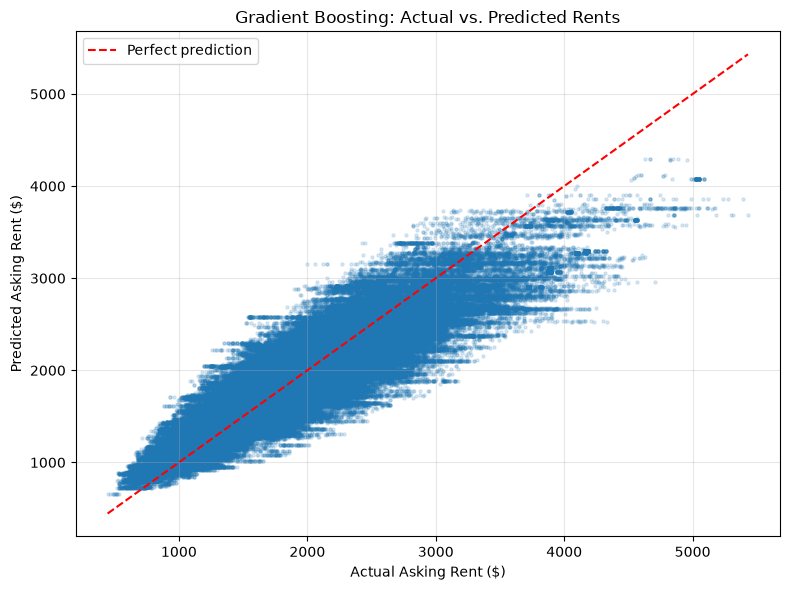

In [11]:

import matplotlib.pyplot as plt

# Actual vs. predicted rents
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_boosting,
    alpha=0.15,
    s=5
)

# Perfect prediction reference line
min_rent = min(y_test.min(), y_pred_boosting.min())
max_rent = max(y_test.max(), y_pred_boosting.max())

plt.plot(
    [min_rent, max_rent],
    [min_rent, max_rent],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Asking Rent ($)")
plt.ylabel("Predicted Asking Rent ($)")
plt.title("Gradient Boosting: Actual vs. Predicted Rents")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Actual vs. Predicted Rents: Initial Findings

The scatter plot shows a positive relationship between actual and predicted asking rents, indicating that the Gradient Boosting model captures the overall rental price pattern.

However, the model appears to systematically overpredict lower rents and underpredict higher rents. Predicted values are also concentrated within a narrower range than actual rents, suggesting a regression-to-the-mean pattern.

These findings indicate that predictive performance may vary across rent levels, even though the model achieves relatively strong aggregate evaluation metrics.

Further residual analysis is needed to quantify these patterns and identify potential systematic prediction errors.

### Residual Analysis

We analyze residuals, defined as the difference between actual and predicted asking rents.

Positive residuals indicate underprediction, while negative residuals indicate overprediction.

Plotting residuals against actual asking rents helps identify systematic prediction biases and assess whether model errors vary across rent levels.

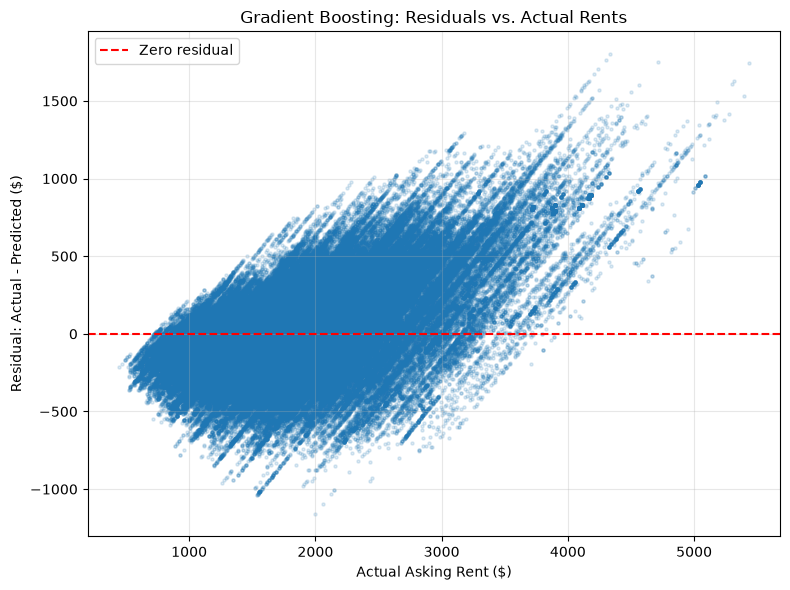

In [12]:

# Calculate residuals
residuals_boosting = y_test - y_pred_boosting

# Plot residuals against actual rents
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    residuals_boosting,
    alpha=0.15,
    s=5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero residual"
)

plt.xlabel("Actual Asking Rent ($)")
plt.ylabel("Residual: Actual - Predicted ($)")
plt.title("Gradient Boosting: Residuals vs. Actual Rents")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Residual Analysis: Initial Findings

The residual plot reveals an apparent systematic pattern in prediction errors.

Residuals tend to be negative for lower asking rents and positive for higher asking rents, suggesting that the model overpredicts lower-priced units and underpredicts higher-priced units.

The spread of residuals also appears to increase with actual rent, indicating potentially larger prediction errors for more expensive units.

Because residuals are plotted against actual rents, part of the observed relationship may arise mechanically. We therefore examine prediction errors across rent intervals to quantify these patterns.

These findings are preliminary and based on synthetic data.

### Prediction Errors by Rent Level

We evaluate model performance across different asking rent intervals.

For each interval, we calculate the number of observations, Mean Absolute Error (MAE), and Mean Error (ME).

Mean Error is defined as actual rent minus predicted rent. Positive values indicate average underprediction, while negative values indicate average overprediction.

This analysis helps determine whether aggregate performance metrics conceal systematic differences across rental price segments.

In [13]:

# Create a DataFrame with actual rents, predictions, and residuals
error_analysis = pd.DataFrame({
    "Actual Rent": y_test.to_numpy(),
    "Predicted Rent": y_pred_boosting
})

error_analysis["Residual"] = (
    error_analysis["Actual Rent"]
    - error_analysis["Predicted Rent"]
)

error_analysis["Absolute Error"] = (
    error_analysis["Residual"].abs()
)

# Define rent intervals
rent_bins = [0, 1000, 1500, 2000, 2500, 3000, 4000, np.inf]

rent_labels = [
    "< $1,000",
    "$1,000–1,500",
    "$1,500–2,000",
    "$2,000–2,500",
    "$2,500–3,000",
    "$3,000–4,000",
    "> $4,000"
]

error_analysis["Rent Interval"] = pd.cut(
    error_analysis["Actual Rent"],
    bins=rent_bins,
    labels=rent_labels,
    include_lowest=True
)

# Summarize errors by rent interval
error_by_rent = (
    error_analysis
    .groupby("Rent Interval", observed=True)
    .agg(
        Observations=("Residual", "size"),
        MAE=("Absolute Error", "mean"),
        Mean_Error=("Residual", "mean")
    )
)

display(error_by_rent.round(2))


,Observations,MAE,Mean_Error
Rent Interval,,,
"< $1,000",11511,185.13,-177.25
"$1,000–1,500",48148,174.35,-109.38
"$1,500–2,000",60275,198.04,-29.53
"$2,000–2,500",44445,235.84,94.15
"$2,500–3,000",20844,330.77,238.65
"$3,000–4,000",11892,496.02,470.81
"> $4,000",1474,853.67,853.67


### Prediction Errors by Rent Level: Findings

The analysis reveals substantial differences in model performance across asking rent intervals.

The model tends to overpredict lower rents and underpredict higher rents. Mean errors change from negative values in the lower rent intervals to increasingly positive values in the higher rent intervals.

Prediction accuracy also deteriorates for more expensive units. MAE increases from approximately $174–$198 for rents below $2,000 to $496 for rents between $3,000 and $4,000, and $854 for rents above $4,000.

For the highest rent interval, the mean error and MAE are both approximately $854, suggesting that nearly all observations in this segment are underpredicted.

These results indicate a potential regression-to-the-mean pattern and highlight the importance of evaluating model performance across different rental market segments.

The findings are exploratory, based on synthetic data, and should be validated using additional data and evaluation strategies.

## 11. Conclusions and Next Steps

This notebook establishes an initial modeling pipeline for predicting residential asking rents using Accolade's synthetic master listing dataset.

Three regression models were developed and evaluated: Linear Regression, Decision Tree, and Histogram-based Gradient Boosting.

**Gradient Boosting achieved the best preliminary performance**, with an MAE of $236.65, RMSE of $308.56, and R² of 0.7896.

The error analysis revealed that prediction accuracy varies across rental price segments, with a tendency to overpredict lower rents and underpredict higher rents.

### Limitations

- All results are based on synthetic data and do not establish real-world predictive accuracy.
- The initial models use only 13 numerical predictors.
- The temporal availability of all selected predictors has not yet been fully verified.
- Hyperparameters have not been systematically optimized.
- The test set has been used for exploratory model comparisons and diagnostics; final model selection will require a separate validation strategy.

### Next Steps

1. Review the schema, quality, and coverage of the real Dwellsy data once available.
2. Verify predictor availability at the time of listing entry and reassess potential data leakage.
3. Incorporate relevant additional features, including categorical location and property characteristics.
4. Perform property-grouped cross-validation and hyperparameter tuning.
5. Compare machine learning predictions against the comparable-properties baseline developed by the team.
6. Conduct a final evaluation using data not involved in model selection.

The current results should be considered a preliminary proof of concept demonstrating that the modeling pipeline can be implemented and evaluated successfully.